<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HecktorGPT2Gen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cuda


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 3.79MB/s]


Patients: 588
HPV class distribution:
 HPV Status
0     58
1    530
Name: count, dtype: int64
Features: ['Age', 'Gender', 'Tobacco Consumption', 'Alcohol Consumption', 'Performance Status', 'T-stage', 'N-stage', 'M-stage']
Train: 381 classes: [ 37 344]
Validation: 89 classes: [ 9 80]
Test: 118 classes: [ 12 106]

Example clinical narrative:
 Q: Predict this patient's Human Papillomavirus (HPV) status using the clinical information available. Age at diagnosis: 66. Gender: male. Tobacco consumption: current smoker. Alcohol consumption: consumes alcohol. Performance status: 0. Tumour stage: T1. Nodal stage: N2. Metastatic stage: M0. Is this patient HPV positive? Answer with only Yes or No.
A:
Target: Yes


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2 hidden size: 768 | Layers: 12 | Heads: 12
Training class weights: [5.1486487  0.55377907]
Epoch 50/500 | Train Loss=0.1476 | Val Loss=2.7799 | Val ROC-AUC=0.4014 | Val PR-AUC=0.8905 | Val BA=0.5437 | Threshold=0.999987
Epoch 100/500 | Train Loss=0.0817 | Val Loss=3.3911 | Val ROC-AUC=0.7250 | Val PR-AUC=0.9635 | Val BA=0.7569 | Threshold=0.999998
Epoch 150/500 | Train Loss=0.0658 | Val Loss=4.2313 | Val ROC-AUC=0.5354 | Val PR-AUC=0.8948 | Val BA=0.6083 | Threshold=0.999998
Epoch 200/500 | Train Loss=0.0963 | Val Loss=2.1117 | Val ROC-AUC=0.4944 | Val PR-AUC=0.8940 | Val BA=0.5847 | Threshold=0.995806
Epoch 250/500 | Train Loss=0.0430 | Val Loss=4.1401 | Val ROC-AUC=0.6181 | Val PR-AUC=0.9396 | Val BA=0.6757 | Threshold=1.000000
Epoch 300/500 | Train Loss=0.0615 | Val Loss=3.7926 | Val ROC-AUC=0.5278 | Val PR-AUC=0.8858 | Val BA=0.5785 | Threshold=0.999793
Epoch 350/500 | Train Loss=0.0706 | Val Loss=3.6977 | Val ROC-AUC=0.4292 | Val PR-AUC=0.8887 | Val BA=0.5493 | Threshold=0.04

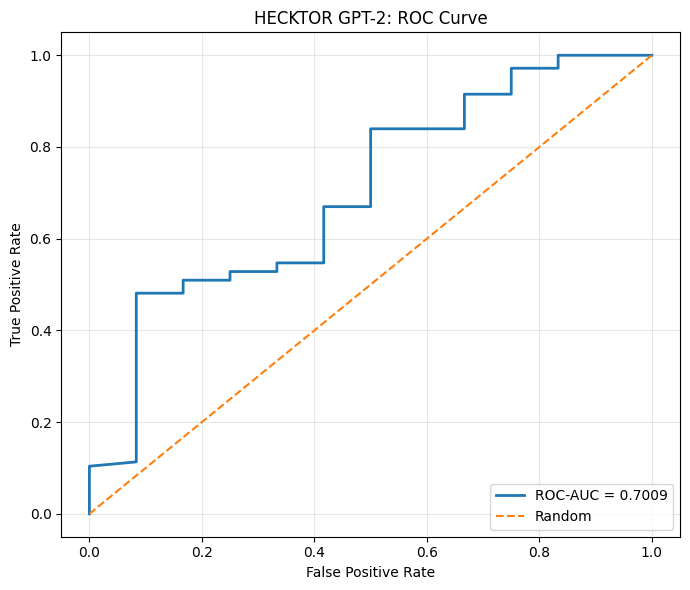

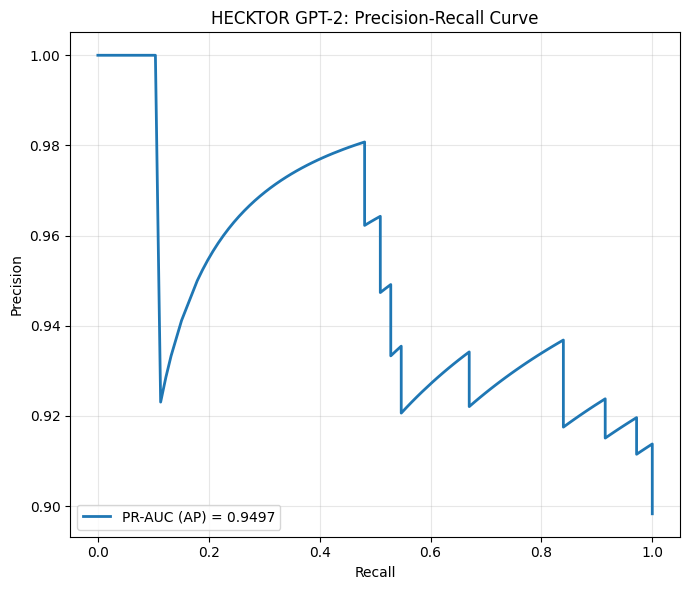


Saved results to: /content/ROC_HECKTOR_GPT2
Optimizer: AdamW | LR: 0.001 | Weight decay: 0.0001
Gradient clipping: None | Early stopping: None
Epochs: 500 | Batch size: 64 | MAX_LENGTH: 96


In [1]:
# ============================================================
# 1. IMPORTS AND REPRODUCIBILITY
# ============================================================
import os,random,json,re,gdown
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import Dataset,DataLoader
from transformers import GPT2Tokenizer,GPT2LMHeadModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,balanced_accuracy_score,roc_auc_score,
    average_precision_score,confusion_matrix,roc_curve,
    precision_recall_curve
)
SEED=42
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
os.environ["PYTHONHASHSEED"]=str(SEED)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:",device)

# ============================================================
# 2. LOAD AND PREPARE HECKTOR DATA
# ============================================================
DATA_FILE="HPV2025.xlsx"
if not os.path.exists(DATA_FILE):
    path=gdown.download(
        id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
        output=DATA_FILE,quiet=False,fuzzy=True
    )
    if path is None or not os.path.exists(DATA_FILE):
        try:
            from google.colab import files
            uploaded=files.upload()
        except ImportError:
            raise FileNotFoundError("Download HPV2025.xlsx and place it beside the notebook.")
        if DATA_FILE not in uploaded:
            raise FileNotFoundError("Please upload HPV2025.xlsx.")
df=pd.read_excel(DATA_FILE)
required=["HPV Status","Age","Gender","Tobacco Consumption",
          "Alcohol Consumption","Performance Status","T-stage","N-stage","M-stage"]
missing=[c for c in required if c not in df.columns]
if missing: raise KeyError(f"Missing columns: {missing}")
df=df.dropna(subset=["HPV Status"]).copy()
df=df.drop(columns=["PatientID","CenterID","Task 1","Task 2","Task 3",
                    "Relapse","RFS","Treatment"],errors="ignore")
df["HPV Status"]=pd.to_numeric(df["HPV Status"],errors="coerce")
df=df[df["HPV Status"].isin([0,1])].copy()
df["HPV Status"]=df["HPV Status"].astype(int)

def stage_num(x):
    if pd.isna(x): return np.nan
    if isinstance(x,str):
        s=x.strip().upper()
        match=re.fullmatch(r"[TNM]\s*(\d+)",s)
        if match: return int(match.group(1))
        try: return float(s)
        except ValueError: return np.nan
    try: return float(x)
    except (TypeError,ValueError): return np.nan

for c in ["T-stage","N-stage","M-stage"]:
    df[c]=df[c].apply(stage_num)

features=[
    "Age","Gender","Tobacco Consumption","Alcohol Consumption",
    "Performance Status","T-stage","N-stage","M-stage"
]
df=df[features+["HPV Status"]].copy()
print("Patients:",len(df))
print("HPV class distribution:\n",df["HPV Status"].value_counts().sort_index())
print("Features:",features)

# ============================================================
# 3. STRATIFIED TRAIN, VALIDATION AND TEST SPLITS
# ============================================================
train_val_df,test_df=train_test_split(
    df,test_size=0.20,random_state=SEED,stratify=df["HPV Status"]
)
train_df,val_df=train_test_split(
    train_val_df,test_size=0.1875,random_state=SEED,
    stratify=train_val_df["HPV Status"]
)
train_df=train_df.copy();val_df=val_df.copy();test_df=test_df.copy()

# Fit imputation values on training data only.
fill_values={}
for c in features:
    if pd.api.types.is_numeric_dtype(train_df[c]):
        value=train_df[c].median()
    else:
        modes=train_df[c].mode(dropna=True)
        value=modes.iloc[0] if not modes.empty else "Unknown"
    if pd.isna(value): value=0 if c in ["Age","T-stage","N-stage","M-stage"] else "Unknown"
    fill_values[c]=value
    for split in [train_df,val_df,test_df]:
        split[c]=split[c].fillna(value)
        if split[c].dtype==object:
            split[c]=split[c].replace("", "Unknown")

y_train=train_df["HPV Status"].to_numpy(dtype=int)
y_val=val_df["HPV Status"].to_numpy(dtype=int)
y_test=test_df["HPV Status"].to_numpy(dtype=int)
print("Train:",len(train_df),"classes:",np.bincount(y_train,minlength=2))
print("Validation:",len(val_df),"classes:",np.bincount(y_val,minlength=2))
print("Test:",len(test_df),"classes:",np.bincount(y_test,minlength=2))

# ============================================================
# 4. CREATE CLINICAL NARRATIVES
# ============================================================
def display_value(x):
    if pd.isna(x): return "Unknown"
    if isinstance(x,(float,np.floating)) and float(x).is_integer():
        return str(int(x))
    return str(x).strip()

def stage_value(prefix,x):
    value=display_value(x)
    if value=="Unknown": return "Unknown"
    return value if value.upper().startswith(prefix) else f"{prefix}{value}"

def patient_to_text(row):
    # Preserve the existing HECKTOR encoding convention:
    # Gender 1=male, 0=female; Tobacco 1=current smoker, 0=non-smoker;
    # Alcohol 1=consumes alcohol, 0=does not consume alcohol.
    gender_value=display_value(row["Gender"])
    tobacco_value=display_value(row["Tobacco Consumption"])
    alcohol_value=display_value(row["Alcohol Consumption"])
    gender={"1":"male","0":"female"}.get(gender_value.lower(),gender_value)
    smoker={"1":"current smoker","0":"non-smoker"}.get(tobacco_value.lower(),tobacco_value)
    alcohol={"1":"consumes alcohol","0":"does not consume alcohol"}.get(alcohol_value.lower(),alcohol_value)
    return (
        "Q: Predict this patient's Human Papillomavirus (HPV) status using "
        "the clinical information available. "
        f"Age at diagnosis: {display_value(row['Age'])}. "
        f"Gender: {gender}. "
        f"Tobacco consumption: {smoker}. "
        f"Alcohol consumption: {alcohol}. "
        f"Performance status: {display_value(row['Performance Status'])}. "
        f"Tumour stage: {stage_value('T',row['T-stage'])}. "
        f"Nodal stage: {stage_value('N',row['N-stage'])}. "
        f"Metastatic stage: {stage_value('M',row['M-stage'])}. "
        "Is this patient HPV positive? Answer with only Yes or No.\nA:"
    )

train_texts=[patient_to_text(r) for _,r in train_df.iterrows()]
val_texts=[patient_to_text(r) for _,r in val_df.iterrows()]
test_texts=[patient_to_text(r) for _,r in test_df.iterrows()]
train_targets=["Yes" if y==1 else "No" for y in y_train]
val_targets=["Yes" if y==1 else "No" for y in y_val]
test_targets=["Yes" if y==1 else "No" for y in y_test]
print("\nExample clinical narrative:\n",train_texts[0])
print("Target:",train_targets[0])

# ============================================================
# 5. CHECK TOKEN LENGTHS BEFORE SETTING MAX_LENGTH
# ============================================================
MODEL_NAME="openai-community/gpt2"
tokenizer=GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token=tokenizer.eos_token
TARGET_LENGTHS=[
    len(tokenizer.encode(" "+target,add_special_tokens=False))+1
    for target in train_targets+val_targets+test_targets
]
ALL_TEXTS=train_texts+val_texts+test_texts
PROMPT_LENGTHS=[
    len(tokenizer.encode(text,add_special_tokens=False))
    for text in ALL_TEXTS
]
REQUIRED_LENGTHS=[
    p+t for p,t in zip(
        PROMPT_LENGTHS,
        TARGET_LENGTHS
    )
]
print("\n===== TOKEN LENGTH CHECK =====")
print("Prompt tokens: min =",min(PROMPT_LENGTHS),
      "| median =",int(np.median(PROMPT_LENGTHS)),
      "| 95th percentile =",int(np.percentile(PROMPT_LENGTHS,95)),
      "| max =",max(PROMPT_LENGTHS))
print("Prompt + answer tokens: max =",max(REQUIRED_LENGTHS))

# Choose a length from the observed data, rounded up to a multiple of 8.
# GPT-2's context window is 1024 tokens.
MAX_LENGTH=min(1024,max(32,int(np.ceil(max(REQUIRED_LENGTHS)/8)*8)))
if max(REQUIRED_LENGTHS)>1024:
    print("WARNING: Some examples exceed GPT-2's 1024-token context window and will be truncated.")
print("Selected MAX_LENGTH:",MAX_LENGTH)
BATCH_SIZE=64
EPOCHS=500
LEARNING_RATE=1e-3
WEIGHT_DECAY=1e-4
print("Batch size:",BATCH_SIZE,"| Epochs:",EPOCHS)

# ============================================================
# 6. TOKENIZER DATASETS
# ============================================================
class GPT2GenerationDataset(Dataset):
    def __init__(self,texts,targets,labels):
        self.items=[]
        for text,target,label in zip(texts,targets,labels):
            prompt_ids=tokenizer.encode(text,add_special_tokens=False)
            target_ids=tokenizer.encode(" "+target,add_special_tokens=False)
            target_ids += [tokenizer.eos_token_id]
            prompt_ids=prompt_ids[:MAX_LENGTH-len(target_ids)]
            ids=prompt_ids+target_ids
            loss_labels=[-100]*len(prompt_ids)+target_ids
            pad_len=MAX_LENGTH-len(ids)
            self.items.append((
                ids+[tokenizer.pad_token_id]*pad_len,
                [1]*len(ids)+[0]*pad_len,
                loss_labels+[-100]*pad_len,
                int(label)
            ))
    def __len__(self): return len(self.items)
    def __getitem__(self,i):
        ids,mask,labels,label=self.items[i]
        return {
            "input_ids":torch.tensor(ids,dtype=torch.long),
            "attention_mask":torch.tensor(mask,dtype=torch.long),
            "labels":torch.tensor(labels,dtype=torch.long),
            "class_label":torch.tensor(label,dtype=torch.long)
        }

train_dataset=GPT2GenerationDataset(train_texts,train_targets,y_train)
val_dataset=GPT2GenerationDataset(val_texts,val_targets,y_val)
test_dataset=GPT2GenerationDataset(test_texts,test_targets,y_test)
train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True)
val_loader=DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False)
test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False)

# ============================================================
# 7. LOAD GPT-2 AND CALCULATE TRAINING-ONLY CLASS WEIGHTS
# ============================================================
model=GPT2LMHeadModel.from_pretrained(MODEL_NAME).to(device)
model.config.pad_token_id=tokenizer.pad_token_id
print("GPT-2 hidden size:",model.config.n_embd,
      "| Layers:",model.config.n_layer,"| Heads:",model.config.n_head)

class_counts=np.bincount(y_train,minlength=2)
class_weights=torch.tensor(
    len(y_train)/(2*np.maximum(class_counts,1)),
    dtype=torch.float32,device=device
)
print("Training class weights:",class_weights.detach().cpu().numpy())
optimizer=torch.optim.AdamW(
    model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY
)

# ============================================================
# 8. CLASS-WEIGHTED GENERATION LOSS
# ============================================================
def weighted_generation_loss(logits,labels,class_labels):
    shift_logits=logits[:,:-1,:].contiguous()
    shift_labels=labels[:,1:].contiguous()
    token_loss=nn.CrossEntropyLoss(reduction="none")(
        shift_logits.reshape(-1,shift_logits.size(-1)),
        shift_labels.reshape(-1)
    ).view(shift_labels.size(0),-1)
    valid=(shift_labels!=-100).float()
    example_loss=(token_loss*valid).sum(1)/valid.sum(1).clamp(min=1)
    return (example_loss*class_weights[class_labels]).mean()

def evaluate_loss(loader):
    model.eval()
    total=0.0
    with torch.no_grad():
        for batch in loader:
            ids=batch["input_ids"].to(device)
            mask=batch["attention_mask"].to(device)
            labels=batch["labels"].to(device)
            classes=batch["class_label"].to(device)
            logits=model(input_ids=ids,attention_mask=mask).logits
            total+=weighted_generation_loss(logits,labels,classes).item()
    return total/max(len(loader),1)

# ============================================================
# 9. CONTINUOUS YES/NO SCORES AND VALIDATION THRESHOLD
# ============================================================
yes_ids=tokenizer.encode(" Yes",add_special_tokens=False)
no_ids=tokenizer.encode(" No",add_special_tokens=False)
if len(yes_ids)!=1 or len(no_ids)!=1:
    raise ValueError("Expected ' Yes' and ' No' to each be a single GPT-2 token.")
YES_TOKEN_ID,NO_TOKEN_ID=yes_ids[0],no_ids[0]

def get_hpv_scores(prompts,batch_size=BATCH_SIZE):
    model.eval()
    scores=[]
    with torch.no_grad():
        for start in range(0,len(prompts),batch_size):
            batch_prompts=prompts[start:start+batch_size]
            encoded=tokenizer(
                batch_prompts,return_tensors="pt",padding=True,
                truncation=True,max_length=MAX_LENGTH
            ).to(device)
            logits=model(
                input_ids=encoded["input_ids"],
                attention_mask=encoded["attention_mask"]
            ).logits
            last_positions=encoded["attention_mask"].sum(dim=1)-1
            next_logits=logits[
                torch.arange(len(batch_prompts),device=device),last_positions
            ]
            probs=torch.softmax(next_logits,dim=-1)
            yes_prob=probs[:,YES_TOKEN_ID]
            no_prob=probs[:,NO_TOKEN_ID]
            scores.extend(
                (yes_prob/(yes_prob+no_prob).clamp(min=1e-12)).cpu().numpy()
            )
    return np.asarray(scores,dtype=float)

def select_threshold(scores,labels):
    # Same method as HANCOCK: maximise balanced accuracy on validation data.
    thresholds=np.unique(np.concatenate((
        [scores.min()-1e-9],scores,[scores.max()+1e-9]
    )))
    results=[
        (float(t),balanced_accuracy_score(labels,(scores>=t).astype(int)))
        for t in thresholds
    ]
    return max(results,key=lambda x:x[1])

# ============================================================
# 10. TRAIN 500 EPOCHS AND SAVE FOUR BEST VALIDATION CHECKPOINTS
# ============================================================
OUT_DIR=Path("ROC_HECKTOR_GPT2")
OUT_DIR.mkdir(parents=True,exist_ok=True)
checkpoint_paths={
    "Validation_Loss":OUT_DIR/"best_model_validation_loss.pth",
    "Validation_ROC_AUC":OUT_DIR/"best_model_validation_roc_auc.pth",
    "Validation_PR_AUC":OUT_DIR/"best_model_validation_pr_auc.pth",
    "Validation_Balanced_Accuracy":OUT_DIR/"best_model_validation_balanced_accuracy.pth"
}
best={
    "Validation_Loss":{"value":float("inf"),"epoch":None,"threshold":None},
    "Validation_ROC_AUC":{"value":-float("inf"),"epoch":None,"threshold":None},
    "Validation_PR_AUC":{"value":-float("inf"),"epoch":None,"threshold":None},
    "Validation_Balanced_Accuracy":{"value":-float("inf"),"epoch":None,"threshold":None}
}
history=[]

for epoch in range(1,EPOCHS+1):
    model.train()
    train_total=0.0
    for batch in train_loader:
        ids=batch["input_ids"].to(device)
        mask=batch["attention_mask"].to(device)
        labels=batch["labels"].to(device)
        classes=batch["class_label"].to(device)
        optimizer.zero_grad(set_to_none=True)
        logits=model(input_ids=ids,attention_mask=mask).logits
        loss=weighted_generation_loss(logits,labels,classes)
        loss.backward()
        # No gradient clipping.
        optimizer.step()
        train_total+=loss.item()

    train_loss=train_total/max(len(train_loader),1)
    val_loss=evaluate_loss(val_loader)
    val_scores=get_hpv_scores(val_texts)
    val_auc=roc_auc_score(y_val,val_scores)
    val_ap=average_precision_score(y_val,val_scores)
    val_threshold,val_ba=select_threshold(val_scores,y_val)

    history.append({
        "Epoch":epoch,"Train_Loss":train_loss,"Validation_Loss":val_loss,
        "Validation_ROC_AUC":val_auc,"Validation_PR_AUC":val_ap,
        "Validation_Balanced_Accuracy":val_ba,
        "Validation_Threshold":val_threshold
    })

    if val_loss<best["Validation_Loss"]["value"]:
        best["Validation_Loss"]={"value":val_loss,"epoch":epoch,"threshold":val_threshold}
        torch.save(model.state_dict(),checkpoint_paths["Validation_Loss"])
    if val_auc>best["Validation_ROC_AUC"]["value"]:
        best["Validation_ROC_AUC"]={"value":val_auc,"epoch":epoch,"threshold":val_threshold}
        torch.save(model.state_dict(),checkpoint_paths["Validation_ROC_AUC"])
    if val_ap>best["Validation_PR_AUC"]["value"]:
        best["Validation_PR_AUC"]={"value":val_ap,"epoch":epoch,"threshold":val_threshold}
        torch.save(model.state_dict(),checkpoint_paths["Validation_PR_AUC"])
    if val_ba>best["Validation_Balanced_Accuracy"]["value"]:
        best["Validation_Balanced_Accuracy"]={"value":val_ba,"epoch":epoch,"threshold":val_threshold}
        torch.save(model.state_dict(),checkpoint_paths["Validation_Balanced_Accuracy"])

    if epoch%50==0:
        print(
            f"Epoch {epoch}/{EPOCHS} | Train Loss={train_loss:.4f} | "
            f"Val Loss={val_loss:.4f} | Val ROC-AUC={val_auc:.4f} | "
            f"Val PR-AUC={val_ap:.4f} | Val BA={val_ba:.4f} | "
            f"Threshold={val_threshold:.6f}"
        )

pd.DataFrame(history).to_csv(OUT_DIR/"training_history.csv",index=False)
best_summary=pd.DataFrame([
    {
        "Checkpoint_Selected_By":metric,"Best_Epoch":info["epoch"],
        "Best_Validation_Metric":info["value"],
        "Threshold_Selected_On_Validation":info["threshold"],
        "Checkpoint_Path":str(checkpoint_paths[metric])
    } for metric,info in best.items()
])
best_summary.to_csv(OUT_DIR/"best_validation_checkpoints.csv",index=False)
print("\n===== BEST VALIDATION CHECKPOINTS =====")
print(best_summary.to_string(index=False))

# ============================================================
# 11. FINAL TEST EVALUATION FOR EACH CHECKPOINT
# ============================================================
# The test set is not used to select checkpoints or thresholds.
test_results=[]
test_predictions={}

for metric,path in checkpoint_paths.items():
    print(f"\n===== Checkpoint selected by {metric} =====")
    model.load_state_dict(torch.load(path,map_location=device))
    scores=get_hpv_scores(test_texts)
    threshold=best[metric]["threshold"]
    pred=(scores>=threshold).astype(int)
    auc=roc_auc_score(y_test,scores)
    ap=average_precision_score(y_test,scores)
    ba=balanced_accuracy_score(y_test,pred)
    cm=confusion_matrix(y_test,pred,labels=[0,1])

    print("Best epoch:",best[metric]["epoch"])
    print("Validation metric:",round(best[metric]["value"],4))
    print(f"Threshold selected on validation: {threshold:.6f}")
    print(classification_report(
        y_test,pred,labels=[0,1],
        target_names=["HPV Negative","HPV Positive"],
        digits=4,zero_division=0
    ))
    print(f"Test ROC-AUC: {auc:.4f}")
    print(f"Test PR-AUC (Average Precision): {ap:.4f}")
    print(f"Test Balanced Accuracy: {ba:.4f}")
    print("Confusion matrix [[TN, FP], [FN, TP]]:\n",cm)

    test_results.append({
        "Checkpoint_Selected_By":metric,
        "Best_Epoch":best[metric]["epoch"],
        "Best_Validation_Metric":best[metric]["value"],
        "Threshold_Selected_On_Validation":threshold,
        "Test_ROC_AUC":auc,"Test_PR_AUC_Average_Precision":ap,
        "Test_Balanced_Accuracy":ba,
        "TN":int(cm[0,0]),"FP":int(cm[0,1]),
        "FN":int(cm[1,0]),"TP":int(cm[1,1])
    })
    test_predictions[metric]={"scores":scores,"predictions":pred,"threshold":threshold}
    pd.DataFrame({
        "True_Label":y_test,"HPV_Positive_Score":scores,
        "Predicted_Label":pred
    }).to_csv(OUT_DIR/f"test_predictions_{metric.lower()}.csv",index=False)

results_df=pd.DataFrame(test_results)
results_df.to_csv(OUT_DIR/"test_metrics_by_checkpoint.csv",index=False)
print("\n===== TEST RESULTS BY CHECKPOINT =====")
print(results_df.to_string(index=False))

# ============================================================
# 12. ROC AND PRECISION-RECALL CURVES
# ============================================================
# Plot the checkpoint selected by validation ROC-AUC.
# The ROC/PR curves use continuous test scores, not a fixed threshold.
primary_metric="Validation_ROC_AUC"
primary_scores=test_predictions[primary_metric]["scores"]
primary_auc=roc_auc_score(y_test,primary_scores)
primary_ap=average_precision_score(y_test,primary_scores)

fpr,tpr,roc_thresholds=roc_curve(y_test,primary_scores)
pd.DataFrame({
    "FPR":fpr,"TPR":tpr,"Threshold":roc_thresholds
}).to_csv(OUT_DIR/"roc_coordinates_best_validation_auc.csv",index=False)

plt.figure(figsize=(7,6))
plt.plot(fpr,tpr,linewidth=2,label=f"ROC-AUC = {primary_auc:.4f}")
plt.plot([0,1],[0,1],"--",linewidth=1.5,label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("HECKTOR GPT-2: ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR/"roc_curve_best_validation_auc.png",dpi=300,bbox_inches="tight")
plt.show()

precision,recall,pr_thresholds=precision_recall_curve(y_test,primary_scores)
pd.DataFrame({"Precision":precision,"Recall":recall}).to_csv(
    OUT_DIR/"precision_recall_coordinates_best_validation_auc.csv",index=False
)
plt.figure(figsize=(7,6))
plt.plot(recall,precision,linewidth=2,label=f"PR-AUC (AP) = {primary_ap:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("HECKTOR GPT-2: Precision-Recall Curve")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR/"precision_recall_curve_best_validation_auc.png",dpi=300,bbox_inches="tight")
plt.show()

# ============================================================
# 13. SAVE SETTINGS AND FINAL SUMMARY
# ============================================================
settings={
    "Dataset":"HECKTOR",
    "Model":MODEL_NAME,
    "Features":", ".join(features),
    "Excluded_Features":"Relapse, RFS, Treatment, PatientID, CenterID, Task 1, Task 2, Task 3",
    "Learning_Rate":LEARNING_RATE,
    "Weight_Decay":WEIGHT_DECAY,
    "Optimizer":"AdamW",
    "Gradient_Clipping":"None",
    "Early_Stopping":"None",
    "Epochs":EPOCHS,
    "Batch_Size":BATCH_SIZE,
    "Max_Length":MAX_LENGTH,
    "Max_Observed_Prompt_And_Target_Tokens":max(REQUIRED_LENGTHS),
    "Random_Seed":SEED,
    "Checkpoint_Selection":"Best validation loss, ROC-AUC, PR-AUC and balanced accuracy",
    "Threshold_Selection":"Maximise validation balanced accuracy separately for each checkpoint",
    "Primary_ROC_PR_Curves":"Checkpoint selected by validation ROC-AUC"
}
pd.DataFrame([settings]).to_csv(OUT_DIR/"settings.csv",index=False)
print("\nSaved results to:",OUT_DIR.resolve())
print("Optimizer: AdamW | LR:",LEARNING_RATE,"| Weight decay:",WEIGHT_DECAY)
print("Gradient clipping: None | Early stopping: None")
print("Epochs:",EPOCHS,"| Batch size:",BATCH_SIZE,"| MAX_LENGTH:",MAX_LENGTH)